# MULUNGUSHI UNIVERSITY
### School of Natural and Applied Sciences – Department of Mathematics and Statistics
## ICD 341 – Advanced Statistical Computing: Labs 5–8

**Name:** BWALYA KASONGO  **Student Number:** 202403418  
**Due:** 19th October 2026, 23:59

In [1]:
# ---- Libraries used throughout Labs 5-8 ----
# Show plots inside the notebook
%matplotlib inline
import numpy as np                 # arrays, linear algebra, random numbers
import pandas as pd                # tidy tables for printing results
import matplotlib.pyplot as plt    # plotting
import scipy.linalg as sla         # extra linear algebra (hilbert, solve_triangular)
import scipy.sparse as sp          # sparse matrices
from scipy import optimize, stats  # optimisers and probability distributions

# Print arrays with 4 decimals and no scientific notation for small numbers
np.set_printoptions(precision=4, suppress=True)

# Random number generator with a fixed seed so results are reproducible
rng = np.random.default_rng(341)

# LAB 5: Linear Systems and Regression with NumPy

## Question 5.1 – Solve  3x + 2y = 12,  x + 4y = 10

Write the system as **A v = b** with A = [[3, 2],[1, 4]], v = [x, y]ᵀ, b = [12, 10]ᵀ.

In [2]:
# Coefficient matrix A: row 1 = 3x + 2y, row 2 = 1x + 4y
A = np.array([[3, 2],
              [1, 4]], dtype=float)

# Right-hand side vector b (the constants 12 and 10)
b = np.array([12, 10], dtype=float)

# Solve A @ [x, y] = b using an LU-based solver
sol = np.linalg.solve(A, b)
print("x =", sol[0], " y =", sol[1])

# Verification: substituting the solution back must reproduce b
print("Check A @ sol =", A @ sol, "(should equal", b, ")")
print("Allclose?", np.allclose(A @ sol, b))   # True if equal within rounding error

x = 2.8000000000000003  y = 1.7999999999999998
Check A @ sol = [12. 10.] (should equal [12. 10.] )
Allclose? True


**Answer:** x = 2.8, y = 1.8 (verified: 3(2.8)+2(1.8)=12 and 2.8+4(1.8)=10).

## Question 5.2 – A 3 × 3 system solved with `np.linalg.solve()`

Solve:  2x + y − z = 8,  −3x − y + 2z = −11,  −2x + y + 2z = −3.

In [3]:
# Coefficient matrix of the 3 x 3 system (each row is one equation)
A3 = np.array([[ 2,  1, -1],
               [-3, -1,  2],
               [-2,  1,  2]], dtype=float)

# Right-hand side of the three equations
b3 = np.array([8, -11, -3], dtype=float)

# A non-zero determinant means the matrix is invertible -> unique solution
print("det(A3) =", round(np.linalg.det(A3), 6), "-> non-zero, so a unique solution exists")

# Solve the system with np.linalg.solve
x3 = np.linalg.solve(A3, b3)
print("Solution [x, y, z] =", x3)

# Residual norm ||A x - b|| should be (almost) zero
print("Residual ||A x - b|| =", np.linalg.norm(A3 @ x3 - b3))

det(A3) = -1.0 -> non-zero, so a unique solution exists
Solution [x, y, z] = [ 2.  3. -1.]
Residual ||A x - b|| = 2.175583928816829e-15


**Answer:** x = 2, y = 3, z = −1.

## Question 5.3 – Why `np.linalg.solve(A, b)` is preferred to computing A⁻¹b

1. **Speed:** `solve` uses an LU factorisation (≈ ⅔n³ flops) and then forward/back substitution. Forming A⁻¹ explicitly needs about 2n³ flops (it solves n systems, one for each column of the identity) and then still needs a matrix–vector multiplication.
2. **Numerical accuracy / stability:** the inverse amplifies rounding error, especially when A is ill-conditioned. `solve` gives a smaller residual and a more accurate answer.
3. **Memory:** the inverse of a sparse or structured matrix is usually dense, destroying structure. `solve` never needs to build it.
4. **Intent:** we only need the vector x, not the whole inverse. Computing the inverse does unnecessary work.
5. **Singularity detection:** `solve` raises a `LinAlgError` when A is singular instead of silently returning garbage.

The demonstration below compares both on an ill-conditioned (Hilbert) matrix.

In [4]:
import time

# Hilbert matrix: a classic ill-conditioned matrix (entries 1/(i+j-1))
n = 12
H = sla.hilbert(n)

# Choose the true solution as all ones, then build b so we know the exact answer
x_true = np.ones(n)
bH = H @ x_true

# Condition number: very large => tiny errors get hugely amplified
print("cond(H) = %.3e" % np.linalg.cond(H))

# Method 1: solve directly.  Method 2: explicit inverse times b
x_solve = np.linalg.solve(H, bH)
x_inv   = np.linalg.inv(H) @ bH

# Compare the error of each method against the known true solution
print("Error with solve : %.3e" % np.linalg.norm(x_solve - x_true))
print("Error with inv@b : %.3e" % np.linalg.norm(x_inv - x_true))

# Timing comparison on a larger random 1500 x 1500 system
M = rng.normal(size=(1500, 1500)); v = rng.normal(size=1500)
t0 = time.perf_counter(); np.linalg.solve(M, v); t1 = time.perf_counter()
np.linalg.inv(M) @ v;                              t2 = time.perf_counter()
print(f"Time solve: {t1-t0:.3f}s | Time inv@b: {t2-t1:.3f}s")

cond(H) = 1.643e+16
Error with solve : 4.467e-01
Error with inv@b : 1.125e+01


Time solve: 0.109s | Time inv@b: 0.333s


## Question 5.4 – Consumption (Y) vs Disposable Income (X), 10 Lusaka households

Model: **Y = β₀ + β₁X + ε**. In matrix form **y = Xβ + ε**, where the design matrix X has a column of ones and a column of incomes.  
The least-squares estimator is **β̂ = (XᵀX)⁻¹Xᵀy**, computed from the normal equations **(XᵀX)β̂ = Xᵀy**.

In [5]:
# Data: disposable income (X) and consumption (Y) for 10 Lusaka households
income      = np.array([30, 45, 60, 100, 150, 200, 240, 250, 300, 320], dtype=float)
consumption = np.array([25, 20, 40,  65, 120, 190, 200, 200, 260, 220], dtype=float)

# (i) Design matrix: first column of ones (intercept), second column = income
X = np.column_stack([np.ones_like(income), income])
y = consumption
print("Design matrix X:\n", X)

# Components of the normal equations (X'X) beta = X'y
XtX = X.T @ X
Xty = X.T @ y
print("\nX'X =\n", XtX)
print("X'y =", Xty)

# Solve the normal equations for the coefficient vector beta = (b0, b1)
beta = np.linalg.solve(XtX, Xty)
b0, b1 = beta
print(f"\nbeta0 (intercept) = {b0:.4f}")
print(f"beta1 (slope)     = {b1:.4f}")
print(f"Fitted model: Consumption = {b0:.4f} + {b1:.4f} * Income")

# Cross-check using NumPy's built-in least-squares routine
print("Check with np.linalg.lstsq:", np.linalg.lstsq(X, y, rcond=None)[0])

Design matrix X:
 [[  1.  30.]
 [  1.  45.]
 [  1.  60.]
 [  1. 100.]
 [  1. 150.]
 [  1. 200.]
 [  1. 240.]
 [  1. 250.]
 [  1. 300.]
 [  1. 320.]]

X'X =
 [[    10.   1695.]
 [  1695. 391525.]]
X'y = [  1340. 312950.]

beta0 (intercept) = -5.5715
beta1 (slope)     = 0.8234
Fitted model: Consumption = -5.5715 + 0.8234 * Income
Check with np.linalg.lstsq: [-5.5715  0.8234]


R-squared = 0.9577,  residual std error = 19.7585
Std errors (b0, b1): [12.1102  0.0612]   t-values: [-0.4601 13.4541]


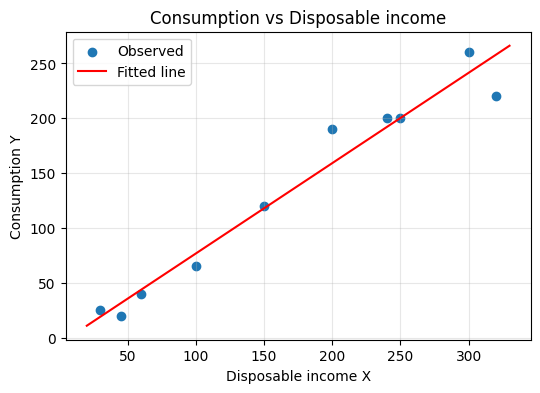

In [6]:
# Goodness of fit: fitted values, residuals and R-squared
y_hat = X @ beta                          # fitted consumption values
resid = y - y_hat                         # residuals (observed - fitted)
SSE = np.sum(resid**2)                    # error (residual) sum of squares
SST = np.sum((y - y.mean())**2)           # total sum of squares
R2 = 1 - SSE/SST                          # proportion of variance explained

# Standard errors of the coefficients: sqrt of diag(sigma^2 (X'X)^-1)
n_obs, p = X.shape
sigma2 = SSE/(n_obs - p)                  # unbiased estimate of error variance
se = np.sqrt(np.diag(sigma2*np.linalg.inv(XtX)))
print(f"R-squared = {R2:.4f},  residual std error = {np.sqrt(sigma2):.4f}")
print("Std errors (b0, b1):", se, "  t-values:", beta/se)

# Scatter plot of the data with the fitted regression line
plt.figure(figsize=(6,4))
plt.scatter(income, consumption, label="Observed")
xs = np.linspace(20, 330, 100)
plt.plot(xs, b0 + b1*xs, color="red", label="Fitted line")
plt.xlabel("Disposable income X"); plt.ylabel("Consumption Y")
plt.title("Consumption vs Disposable income"); plt.legend(); plt.grid(alpha=.3)
plt.show()

In [7]:
# (ii) Predicted consumption for a household with disposable income 181
x_new = 181
# Row vector [1, x_new] times beta = b0 + b1 * x_new
pred = np.array([1, x_new]) @ beta
print(f"Estimated consumption at income {x_new}: {pred:.4f}")

Estimated consumption at income 181: 143.4695


**Answer (ii):** substituting X = 181 into the fitted line gives the estimated consumption printed above (≈ 143.47, i.e. -5.5715 + 0.8234 × 181).

# LAB 6: Matrix Decompositions and Sparse Matrices

## Question 6.1 – Covariance matrix and Cholesky decomposition

A valid covariance matrix Σ is symmetric positive definite, so it can be written **Σ = L Lᵀ** with L lower-triangular.

In [8]:
# Simulate 200 observations of 3 correlated variables (mixing independent normals)
data = rng.normal(size=(200, 3)) @ np.array([[2.0, 0.5, 0.3],
                                             [0.0, 1.5, 0.4],
                                             [0.0, 0.0, 1.0]])

# Sample covariance matrix (rowvar=False -> columns are variables)
Sigma = np.cov(data, rowvar=False)
print("Covariance matrix Sigma:\n", Sigma)

# A covariance matrix must be symmetric and positive definite
print("Symmetric?", np.allclose(Sigma, Sigma.T))
print("Eigenvalues (all > 0 => positive definite):", np.linalg.eigvalsh(Sigma))

# Cholesky decomposition: Sigma = L L^T with L lower triangular
L = np.linalg.cholesky(Sigma)
print("\nCholesky factor L:\n", L)
print("Reconstruction L @ L.T equals Sigma?", np.allclose(L @ L.T, Sigma))

# Application: turn independent N(0,1) numbers into correlated ones with covariance Sigma
Z = rng.normal(size=(100000, 3))
Y = Z @ L.T
print("\nCovariance of simulated data (should be close to Sigma):\n", np.cov(Y, rowvar=False))

Covariance matrix Sigma:
 [[4.0911 0.8178 0.2507]
 [0.8178 2.6258 0.4643]
 [0.2507 0.4643 0.9672]]
Symmetric? True
Eigenvalues (all > 0 => positive definite): [0.8456 2.332  4.5066]

Cholesky factor L:
 [[2.0227 0.     0.    ]
 [0.4043 1.5692 0.    ]
 [0.1239 0.264  0.9392]]
Reconstruction L @ L.T equals Sigma? True

Covariance of simulated data (should be close to Sigma):
 [[4.1187 0.8254 0.2496]
 [0.8254 2.6324 0.4607]
 [0.2496 0.4607 0.9642]]


## Question 6.2 – QR decomposition  (A = QR)

In [9]:
# A square matrix to decompose
A = np.array([[12, -51,   4],
              [ 6, 167, -68],
              [-4,  24, -41]], dtype=float)

# QR decomposition: A = Q R, Q orthogonal, R upper triangular
Q, R = np.linalg.qr(A)
print("Q:\n", Q); print("R (upper triangular):\n", R)

# Checks: Q^T Q = identity (orthogonality) and Q R reproduces A
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(3)))
print("QR = A  ?", np.allclose(Q @ R, A))

# Use of QR: solve a least-squares problem (more stable than normal equations)
Xd = np.column_stack([np.ones(10), np.arange(10)])             # design matrix
yd = 3 + 2*np.arange(10) + rng.normal(scale=.5, size=10)       # noisy straight line
Qd, Rd = np.linalg.qr(Xd)
# R beta = Q^T y is a triangular system, solved by back-substitution
print("Least-squares coefficients via QR:", sla.solve_triangular(Rd, Qd.T @ yd))

Q:
 [[-0.8571  0.3943  0.3314]
 [-0.4286 -0.9029 -0.0343]
 [ 0.2857 -0.1714  0.9429]]
R (upper triangular):
 [[ -14.  -21.   14.]
 [   0. -175.   70.]
 [   0.    0.  -35.]]
Q^T Q = I ? True
QR = A  ? True
Least-squares coefficients via QR: [3.2404 1.9305]


## Question 6.3 – Reconstruct a matrix using SVD  (A = U Σ Vᵀ)

In [10]:
# Create a random 5 x 4 integer matrix (values 1 to 9)
A = rng.integers(1, 10, size=(5, 4)).astype(float)
print("A:\n", A)

# Singular value decomposition: A = U diag(s) V^T
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("\nSingular values:", s)

# Rebuild the matrix from its three factors
A_rec = U @ np.diag(s) @ Vt
print("Full reconstruction equals A?", np.allclose(A, A_rec))
print("Max abs error:", np.abs(A - A_rec).max())

# Low-rank approximation: keep only the k largest singular values
k = 2
A_k = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
print("\nRank-2 approximation:\n", A_k)

# Approximation error equals the root of the sum of squares of the dropped singular values
print("Frobenius error:", np.linalg.norm(A - A_k), " (= sqrt of sum of dropped s^2 =",
      np.sqrt(np.sum(s[k:]**2)), ")")

A:
 [[4. 3. 6. 9.]
 [6. 6. 5. 2.]
 [9. 7. 2. 7.]
 [4. 4. 4. 1.]
 [9. 1. 8. 8.]]

Singular values: [24.4617  7.1873  4.843   3.3934]
Full reconstruction equals A? True
Max abs error: 7.993605777301127e-15

Rank-2 approximation:
 [[5.9181 1.5349 6.1221 7.7248]
 [6.4235 5.8869 3.1094 3.1964]
 [8.5237 7.058  4.7574 5.168 ]
 [4.3479 3.9405 2.1417 2.218 ]
 [7.4539 2.229  7.463  9.3659]]
Frobenius error: 5.913573903409526  (= sqrt of sum of dropped s^2 = 5.913573903409524 )


## Question 6.4 – Condition number of a matrix

The condition number κ(A) = σ_max / σ_min measures sensitivity of the solution of Ax = b to small perturbations. Large κ ⇒ ill-conditioned.

In [11]:
# Three matrices: well-conditioned, nearly singular, and an 8 x 8 Hilbert matrix
A_good = np.array([[2., 0.], [0., 1.]])
A_bad  = np.array([[1., 1.], [1., 1.0001]])
H8 = sla.hilbert(8)

# np.linalg.cond uses the 2-norm: ratio of largest to smallest singular value
for name, M in [("Well-conditioned", A_good), ("Nearly singular", A_bad), ("Hilbert 8x8", H8)]:
    print(f"{name:18s} cond (2-norm) = {np.linalg.cond(M):.4e}")

# Verify the definition cond = sigma_max / sigma_min using the SVD
s = np.linalg.svd(A_bad, compute_uv=False)
print("\nsigma_max/sigma_min for A_bad:", s[0]/s[-1])

# Demonstrate sensitivity: a tiny change in b changes the solution dramatically
b = np.array([2., 2.0001])
print("Solution for b:", np.linalg.solve(A_bad, b))
print("Solution for slightly perturbed b:", np.linalg.solve(A_bad, b + np.array([0, 0.0001])))

Well-conditioned   cond (2-norm) = 2.0000e+00
Nearly singular    cond (2-norm) = 4.0002e+04
Hilbert 8x8        cond (2-norm) = 1.5258e+10

sigma_max/sigma_min for A_bad: 40002.000074915224
Solution for b: [1. 1.]
Solution for slightly perturbed b: [-0.  2.]


## Question 6.5 – Create a sparse 1000 × 1000 matrix

In [12]:
n = 1000

# Random 1000 x 1000 sparse matrix with only 1% non-zero entries (CSR format)
S = sp.random(n, n, density=0.01, format="csr", random_state=341)
print("Shape:", S.shape, "| non-zero entries:", S.nnz, "| density:", S.nnz/n**2)
print("Format:", S.format)

# Look at a small corner after converting it to a dense array
print("Top-left 5x5 block:\n", S[:5, :5].toarray())

# Another sparse example: tridiagonal matrix with -1, 2, -1 on the diagonals
T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n), format="csr")
print("\nTridiagonal matrix nnz:", T.nnz)

# Sparse matrix-vector products work directly without making the matrix dense
v = rng.normal(size=n)
print("Sparse mat-vec result (first 5):", (S @ v)[:5])

Shape: (1000, 1000) | non-zero entries: 10000 | density: 0.01
Format: csr
Top-left 5x5 block:
 [[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]

Tridiagonal matrix nnz: 2998
Sparse mat-vec result (first 5): [ 3.9569 -0.6073 -0.5683  1.5005 -0.3184]


## Question 6.6 – Why sparse matrices are useful for large datasets

* **Memory:** only the non-zero values and their positions are stored (e.g. CSR keeps `data`, `indices`, `indptr`). A 1000×1000 matrix with 1% non-zeros needs ~1% of the memory of the dense version; a 10⁶×10⁶ matrix would be impossible to store densely.
* **Speed:** operations such as matrix–vector products touch only non-zero entries: cost O(nnz) instead of O(n²).
* **Scalable algorithms:** sparse solvers and iterative methods (`scipy.sparse.linalg`) solve huge systems that dense solvers cannot.
* **Natural fit for real data:** text/bag-of-words data, one-hot encodings, recommender-system matrices, graphs/networks and finite-element models are mostly zeros.

In [13]:
# Dense copy of the sparse matrix, to compare memory use
dense = S.toarray()

# Memory of the sparse version = values + column indices + row pointers
sparse_bytes = S.data.nbytes + S.indices.nbytes + S.indptr.nbytes
print(f"Dense storage : {dense.nbytes/1e6:.2f} MB")
print(f"Sparse storage: {sparse_bytes/1e6:.3f} MB")

# Time 200 matrix-vector products for each representation
import time
t0=time.perf_counter()
for _ in range(200): dense @ v
t1=time.perf_counter()
for _ in range(200): S @ v
t2=time.perf_counter()
print(f"200 mat-vec products: dense {t1-t0:.4f}s vs sparse {t2-t1:.4f}s")

Dense storage : 8.00 MB
Sparse storage: 0.124 MB
200 mat-vec products: dense 0.0485s vs sparse 0.0022s


# LAB 7: Optimization, MLE and Logistic Regression

## Question 7.1 – Gradient descent to minimise f(x) = (x − 10)²

f′(x) = 2(x − 10). Update rule: **xₖ₊₁ = xₖ − α f′(xₖ)**. The minimum is at x = 10.

Minimiser x* = 10.000000, f(x*) = 2.47e-17, iterations = 96


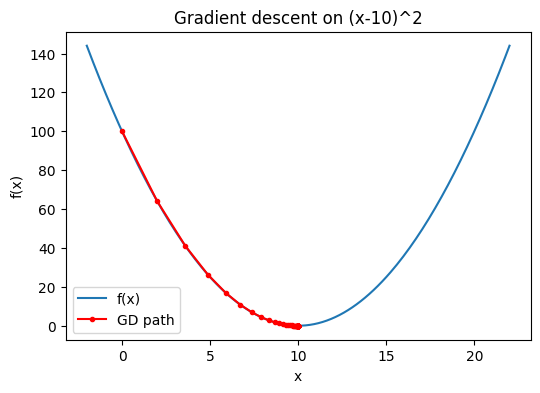

In [14]:
# Objective function f(x) = (x - 10)^2 and its derivative f'(x) = 2(x - 10)
def f(x):      return (x - 10)**2
def grad_f(x): return 2*(x - 10)

def gradient_descent(x0, lr=0.1, tol=1e-8, max_iter=10000):
    # Minimise f by repeatedly stepping against the gradient
    x = x0
    path = [x]                      # store every iterate to plot later
    for i in range(max_iter):
        g = grad_f(x)
        if abs(g) < tol:            # stop when the gradient is almost zero
            break
        x = x - lr*g                # update rule: x_new = x - lr * f'(x)
        path.append(x)
    return x, np.array(path)

# Start from x = 0 with learning rate 0.1
x_min, path = gradient_descent(x0=0.0, lr=0.1)
print(f"Minimiser x* = {x_min:.6f}, f(x*) = {f(x_min):.2e}, iterations = {len(path)-1}")

# Plot the function and the path taken by gradient descent
xs = np.linspace(-2, 22, 200)
plt.figure(figsize=(6,4))
plt.plot(xs, f(xs), label="f(x)")
plt.plot(path, f(path), "o-", ms=3, color="red", label="GD path")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("Gradient descent on (x-10)^2"); plt.legend()
plt.show()

## Question 7.2 – Compare BFGS and CG on f(x, y) = (x − 4)² + (y − 6)²

In [15]:
# Two-variable objective f(x, y) = (x - 4)^2 + (y - 6)^2 and its gradient
def f2(p):    return (p[0]-4)**2 + (p[1]-6)**2
def g2(p):    return np.array([2*(p[0]-4), 2*(p[1]-6)])

# Starting point for both optimisers
x0 = np.array([0.0, 0.0])

# Run BFGS and CG with the same objective, gradient and start, then collect statistics
rows = []
for method in ["BFGS", "CG"]:
    res = optimize.minimize(f2, x0, jac=g2, method=method)
    rows.append({"Method": method, "x*": res.x[0], "y*": res.x[1], "f(min)": res.fun,
                 "Iterations": res.nit, "f evals": res.nfev, "grad evals": res.njev,
                 "Success": res.success})

# Show the comparison table
print(pd.DataFrame(rows).to_string(index=False))

Method  x*  y*       f(min)  Iterations  f evals  grad evals  Success
  BFGS 4.0 6.0 1.577722e-30           3        4           4     True
    CG 4.0 6.0 0.000000e+00           2        5           5     True


**Comment:** both methods reach the true minimum (4, 6) with f = 0. BFGS (a quasi-Newton method) builds an approximation to the inverse Hessian and uses more memory (O(n²)); Conjugate Gradient (CG) stores only a few vectors (O(n)) and is therefore preferred for very high-dimensional problems. On this simple quadratic both converge in very few iterations.

## Question 7.3 – Effect of changing the learning rate

For f(x) = (x − 10)², xₖ₊₁ − 10 = (1 − 2α)(xₖ − 10). Hence:  
* **0 < α < 0.5:** smooth monotone convergence (small α is slow);  
* **α = 0.5:** converges in one step;  
* **0.5 < α < 1:** oscillates around the minimum but still converges;  
* **α = 1:** oscillates forever between two values; **α > 1:** diverges.

 learning rate  x after 100 iters         f(x)
         0.001           1.814332 6.700516e+01
         0.010           8.673804 1.758795e+00
         0.100          10.000000 4.149521e-18
         0.500          10.000000 0.000000e+00
         0.900          10.000000 4.149521e-18
         1.000           0.000000 1.000000e+02
         1.050     -137796.123398 1.899053e+10


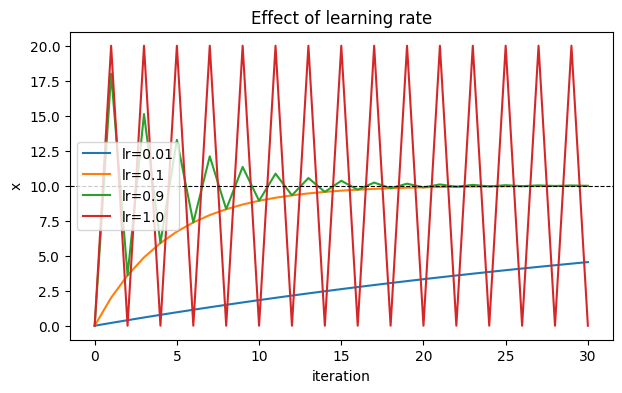

In [16]:
# Learning rates to compare (alpha); the theory says convergence needs 0 < alpha < 1
lrs = [0.001, 0.01, 0.1, 0.5, 0.9, 1.0, 1.05]

# Run 100 gradient descent steps from x = 0 for each learning rate
rows = []
for lr in lrs:
    x = 0.0
    for i in range(100):
        x = x - lr*grad_f(x)
    rows.append({"learning rate": lr, "x after 100 iters": x, "f(x)": f(x)})
print(pd.DataFrame(rows).to_string(index=False))

# Plot the first 30 iterates for four learning rates
plt.figure(figsize=(7,4))
for lr in [0.01, 0.1, 0.9, 1.0]:
    x = 0.0; trace = [x]
    for i in range(30):
        x = x - lr*grad_f(x); trace.append(x)
    plt.plot(trace, label=f"lr={lr}")
plt.axhline(10, color="k", ls="--", lw=.8)       # true minimiser x = 10
plt.xlabel("iteration"); plt.ylabel("x"); plt.legend(); plt.title("Effect of learning rate")
plt.show()

**Conclusion:** a learning rate that is too small makes convergence very slow; one that is too large causes oscillation or divergence. A good learning rate balances speed and stability.

## Question 7.4 – MLE of the mean of normal observations with SciPy

For X₁,…,Xₙ ~ N(μ, σ²) the log-likelihood is  
ℓ(μ, σ) = −n log σ − (n/2) log(2π) − Σ(xᵢ − μ)² / (2σ²).  
We minimise the **negative** log-likelihood numerically.

In [17]:
# Simulate 200 observations from N(mu = 5, sigma = 2); the MLE should recover these values
true_mu, true_sigma, n = 5.0, 2.0, 200
obs = rng.normal(true_mu, true_sigma, size=n)

# (a) Estimate mu only (sigma assumed known): minimise the negative log-likelihood
def nll_mu(params):
    mu = params[0]
    return -np.sum(stats.norm.logpdf(obs, loc=mu, scale=true_sigma))

res_a = optimize.minimize(nll_mu, x0=[0.0], method="BFGS")
print("MLE of mu (sigma known):", res_a.x[0])

# (b) Estimate mu and sigma together; optimise log(sigma) so sigma stays positive
def nll_both(params):
    mu, log_sigma = params
    return -np.sum(stats.norm.logpdf(obs, loc=mu, scale=np.exp(log_sigma)))

res_b = optimize.minimize(nll_both, x0=[0.0, 0.0], method="BFGS")
mu_hat, sigma_hat = res_b.x[0], np.exp(res_b.x[1])
print(f"MLE of mu = {mu_hat:.5f}, MLE of sigma = {sigma_hat:.5f}")

# Compare with the closed-form MLEs and SciPy's built-in fit
print("\nSample mean (closed-form MLE):", obs.mean())
print("Sample std with ddof=0         :", obs.std(ddof=0))
print("Check with scipy.stats.norm.fit:", stats.norm.fit(obs))

MLE of mu (sigma known): 5.11875518566182
MLE of mu = 5.11876, MLE of sigma = 2.03180

Sample mean (closed-form MLE): 5.118755097364255
Sample std with ddof=0         : 2.0318003962814393
Check with scipy.stats.norm.fit: (np.float64(5.118755097364255), np.float64(2.0318003962814393))


**Conclusion:** the numerical MLE of μ equals the sample mean x̄ (the analytic MLE), and σ̂ equals the divisor-n standard deviation.

## Question 7.5 – Sigmoid function  σ(z) = 1 / (1 + e⁻ᶻ)

sigmoid(0)   = 0.5
sigmoid(2)   = 0.8807970779778823
sigmoid(-2)  = 0.11920292202211755
sigmoid(-1000), sigmoid(1000) = 0.0 1.0


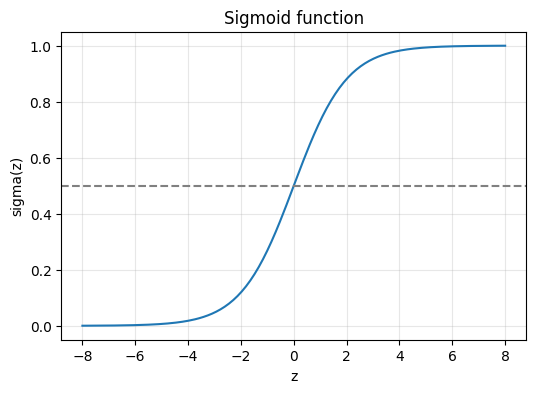

In [18]:
def sigmoid(z):
    # Numerically stable sigmoid: 1 / (1 + exp(-z))
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    # For z >= 0 use 1/(1+e^-z): the exponent is <= 0, so no overflow
    out[pos]  = 1.0/(1.0 + np.exp(-z[pos]))
    # For z < 0 use e^z/(1+e^z): avoids overflow of e^-z for large negative z
    ez = np.exp(z[~pos])
    out[~pos] = ez/(1.0 + ez)
    return out

# Test values: sigmoid(0) = 0.5, symmetry sigmoid(-z) = 1 - sigmoid(z), and extreme inputs
print("sigmoid(0)   =", sigmoid(0.0))
print("sigmoid(2)   =", sigmoid(2.0))
print("sigmoid(-2)  =", sigmoid(-2.0))
print("sigmoid(-1000), sigmoid(1000) =", sigmoid(-1000.0), sigmoid(1000.0))

# Plot the S-shaped curve
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6,4)); plt.plot(z, sigmoid(z)); plt.axhline(.5, ls="--", c="gray")
plt.xlabel("z"); plt.ylabel("sigma(z)"); plt.title("Sigmoid function"); plt.grid(alpha=.3); plt.show()

## Question 7.6 – Simple logistic regression by MLE

Model: P(Yᵢ = 1 | xᵢ) = pᵢ = σ(β₀ + β₁xᵢ).  
Log-likelihood: ℓ(β) = Σ [ yᵢ log pᵢ + (1 − yᵢ) log(1 − pᵢ) ].  
We minimise −ℓ(β) with SciPy.

In [19]:
# Data: study hours (X) and pass/fail outcome (Y)
hours = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
Yp    = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=float)

# Design matrix with an intercept column
Xd    = np.column_stack([np.ones_like(hours), hours])

# Negative log-likelihood: sum[ log(1 + e^eta) - y*eta ], where eta = b0 + b1*x
# (np.logaddexp(0, eta) computes log(1 + e^eta) without overflow)
def neg_loglik(beta):
    eta = Xd @ beta
    return np.sum(np.logaddexp(0, eta) - Yp*eta)

# Gradient of the negative log-likelihood: X^T (p - y)
def neg_grad(beta):
    return Xd.T @ (sigmoid(Xd @ beta) - Yp)

# Maximum likelihood = minimise the negative log-likelihood, starting from beta = (0, 0)
res = optimize.minimize(neg_loglik, x0=np.zeros(2), jac=neg_grad, method="BFGS")
print(res.message)
print("beta0, beta1 =", res.x, "| max log-likelihood =", -res.fun)

Optimization terminated successfully.
beta0, beta1 = [-127.1922   28.0472] | max log-likelihood = -2.4683984946997168e-06


### Important observation: complete separation

All students who studied ≤ 4 hours failed and all who studied ≥ 5 hours passed – the data are **perfectly (completely) separated**. For such data the unpenalised MLE does **not exist** as a finite number: the likelihood keeps increasing towards 0 (log-likelihood → 0) as β₁ → ∞. The optimiser therefore just stops at a very large slope when it reaches its tolerance, as shown above. The decision boundary, however, is stable: it is at x = −β₀/β₁ ≈ 4.5 hours.

To obtain finite, usable estimates we add a tiny L2 (ridge) penalty – the standard remedy (Firth/penalised logistic regression gives the same idea).

Penalised fit: beta0 = -12.0463, beta1 = 2.6770
Decision boundary (p = 0.5): x = 4.500 hours
Odds ratio per extra hour  : 14.541

Fitted probabilities: [0.0001 0.0012 0.0177 0.2078 0.7922 0.9823 0.9988 0.9999]
Predicted classes   : [0 0 0 0 1 1 1 1] | Actual: [0 0 0 0 1 1 1 1]
Training accuracy   : 1.0
P(pass | 4.5 hrs) = 0.5000000754011622


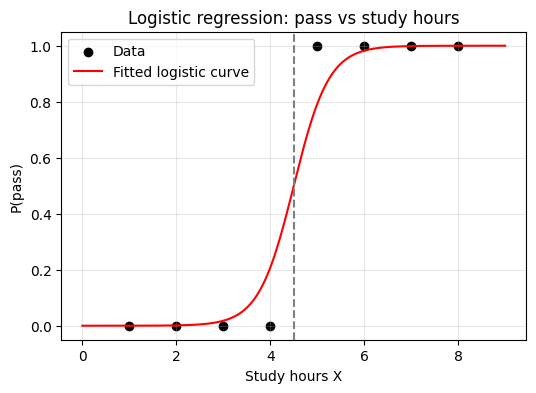

In [20]:
# Penalised (ridge) negative log-likelihood: adds 0.5*lam*beta1^2 (intercept not penalised)
def pen_nll(beta, lam=0.1):
    return neg_loglik(beta) + 0.5*lam*beta[1]**2

# Its gradient: the penalty adds lam*beta1 to the slope component
def pen_grad(beta, lam=0.1):
    g = neg_grad(beta).copy(); g[1] += lam*beta[1]; return g

# Fit the penalised model; the penalty keeps the estimates finite
res_p = optimize.minimize(pen_nll, np.zeros(2), jac=pen_grad, method="BFGS")
b0_hat, b1_hat = res_p.x
print(f"Penalised fit: beta0 = {b0_hat:.4f}, beta1 = {b1_hat:.4f}")

# Study hours at which P(pass) = 0.5, i.e. beta0 + beta1*x = 0
print(f"Decision boundary (p = 0.5): x = {-b0_hat/b1_hat:.3f} hours")
# exp(beta1) = factor by which the odds of passing grow per extra hour
print(f"Odds ratio per extra hour  : {np.exp(b1_hat):.3f}")

# Fitted probabilities, predicted classes (threshold 0.5) and accuracy
pred_p = sigmoid(Xd @ res_p.x)
print("\nFitted probabilities:", pred_p)
print("Predicted classes   :", (pred_p >= .5).astype(int), "| Actual:", Yp.astype(int))
print("Training accuracy   :", np.mean((pred_p >= .5) == Yp))
print("P(pass | 4.5 hrs) =", float(sigmoid(b0_hat + b1_hat*4.5)))

# Plot the data points and the fitted logistic curve
grid = np.linspace(0, 9, 200)
plt.figure(figsize=(6,4))
plt.scatter(hours, Yp, c="black", label="Data")
plt.plot(grid, sigmoid(b0_hat + b1_hat*grid), c="red", label="Fitted logistic curve")
plt.axvline(-b0_hat/b1_hat, ls="--", c="gray")     # decision boundary
plt.xlabel("Study hours X"); plt.ylabel("P(pass)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Logistic regression: pass vs study hours"); plt.show()

# LAB 8: Random Number Generation and Monte Carlo Methods

## Question 8.1 – Generate 10 000 observations from N(50, 10²)

First 5 values: [52.2932 52.1166 46.4632 25.8546 58.1002]
Sample mean = 50.0823 (theory 50)
Sample std  = 10.1084 (theory 10)


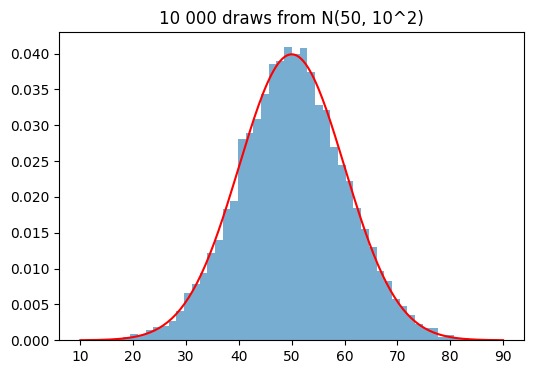

In [21]:
N = 10_000

# 10 000 draws from N(50, 10^2): loc = mean, scale = standard deviation (10, not variance 100)
normal_obs = rng.normal(loc=50, scale=10, size=N)
print("First 5 values:", normal_obs[:5])

# Sample statistics should be close to the theoretical mean 50 and standard deviation 10
print(f"Sample mean = {normal_obs.mean():.4f} (theory 50)")
print(f"Sample std  = {normal_obs.std(ddof=1):.4f} (theory 10)")

# Histogram of the sample with the true N(50, 10^2) density overlaid
plt.figure(figsize=(6,4))
plt.hist(normal_obs, bins=50, density=True, alpha=.6)
xs = np.linspace(10, 90, 200); plt.plot(xs, stats.norm.pdf(xs, 50, 10), "r")
plt.title("10 000 draws from N(50, 10^2)"); plt.show()

## Question 8.2 – 10 000 Bernoulli(p = 0.3) observations and sample proportion

In [22]:
# 10 000 Bernoulli(0.3) trials (a Binomial with n = 1): 1 = success, 0 = failure
bern = rng.binomial(n=1, p=0.3, size=N)

# Sample proportion of successes = mean of the 0/1 values
p_hat = bern.mean()
print("Number of successes:", bern.sum())
print(f"Sample proportion of successes = {p_hat:.4f} (true p = 0.3)")

# Theoretical standard error of a proportion: sqrt(p(1-p)/N)
print(f"Standard error = {np.sqrt(0.3*0.7/N):.4f}")

Number of successes: 3010
Sample proportion of successes = 0.3010 (true p = 0.3)
Standard error = 0.0046


## Question 8.3 – Monte Carlo estimate of ∫₀¹ x³ dx

Exact value = 1/4. If U ~ U(0,1) then ∫₀¹ x³dx = E[U³], estimated by the mean of Uᵢ³.

In [23]:
# One million uniform random numbers on (0, 1)
M = 1_000_000
u = rng.uniform(0, 1, M)

# Integral of x^3 over (0,1) = E[U^3]; the sample mean of U^3 estimates it
h = u**3
est = h.mean(); se = h.std(ddof=1)/np.sqrt(M)      # estimate and its standard error
print(f"MC estimate = {est:.6f}  (SE = {se:.6f})")
print(f"95% CI      = ({est-1.96*se:.6f}, {est+1.96*se:.6f})")
print("Exact value = 0.25  | absolute error =", abs(est-0.25))

MC estimate = 0.250096  (SE = 0.000284)
95% CI      = (0.249540, 0.250652)
Exact value = 0.25  | absolute error = 9.60808056153506e-05


## Question 8.4 – Estimate π using one million points

Generate (x, y) uniformly in the unit square. The quarter circle x² + y² ≤ 1 has area π/4, so **π ≈ 4 × (fraction of points inside)**.

Estimate of pi = 3.14448   (SE ~ 0.00164)
True pi        = 3.14159   | error = 0.00289


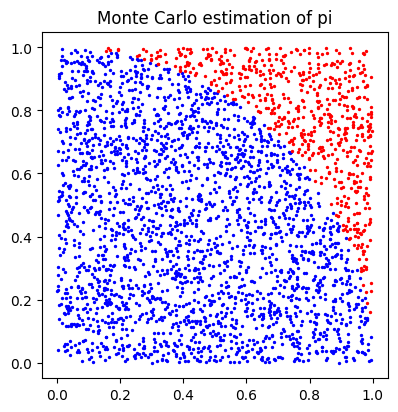

In [24]:
# One million random points in the unit square [0,1] x [0,1]
M = 1_000_000
px = rng.uniform(0, 1, M); py = rng.uniform(0, 1, M)

# A point lies inside the quarter circle when x^2 + y^2 <= 1
inside = (px**2 + py**2) <= 1

# Area of quarter circle = pi/4, so pi is estimated by 4 * (fraction of points inside)
pi_hat = 4*inside.mean()
se_pi = 4*np.sqrt(inside.mean()*(1-inside.mean())/M)    # standard error of the estimate
print(f"Estimate of pi = {pi_hat:.5f}   (SE ~ {se_pi:.5f})")
print(f"True pi        = {np.pi:.5f}   | error = {abs(pi_hat-np.pi):.5f}")

# Visualise the first 3000 points: blue = inside the circle, red = outside
plt.figure(figsize=(4.5,4.5))
k = 3000
plt.scatter(px[:k][inside[:k]], py[:k][inside[:k]], s=2, c="blue")
plt.scatter(px[:k][~inside[:k]], py[:k][~inside[:k]], s=2, c="red")
plt.gca().set_aspect("equal"); plt.title("Monte Carlo estimation of pi"); plt.show()

## Question 8.5 – Estimate P(X > 1.96) where X ~ N(0, 1)

In [25]:
# Plain Monte Carlo for P(X > 1.96): draw standard normal values and count exceedances
M = 1_000_000
z = rng.standard_normal(M)
ind = (z > 1.96)                                   # indicator: 1 if X > 1.96
p_mc = ind.mean(); se_mc = np.sqrt(p_mc*(1-p_mc)/M)
print(f"Monte Carlo estimate      = {p_mc:.6f}  (SE = {se_mc:.6f})")
# Exact tail probability from the normal survival function 1 - Phi(1.96)
print(f"Exact value 1 - Phi(1.96) = {stats.norm.sf(1.96):.6f}")

# Bonus: importance sampling with proposal N(1.96, 1), which puts many samples in the tail
y = rng.normal(1.96, 1, M)
w = stats.norm.pdf(y)/stats.norm.pdf(y, loc=1.96)   # weights f(y)/g(y)
is_vals = (y > 1.96)*w
print(f"Importance-sampling estimate = {is_vals.mean():.6f}  (SE = {is_vals.std(ddof=1)/np.sqrt(M):.6f})")

Monte Carlo estimate      = 0.024735  (SE = 0.000155)
Exact value 1 - Phi(1.96) = 0.024998


Importance-sampling estimate = 0.024943  (SE = 0.000038)


**Answer:** P(X > 1.96) ≈ 0.025 (exact 0.0249979).

## Question 8.6 – Importance sampling to estimate E(X²), X ~ U(0, 1)

Exact value: ∫₀¹ x² dx = 1/3.

Importance sampling rewrites E_f[h(X)] = E_g[h(X) f(X)/g(X)], with samples drawn from a proposal g.  
Choose g(x) = 2x on (0,1) (a Beta(2,1) density), which puts more mass where x² is large. Sampling: X = √U (inverse CDF, since G(x) = x²). Weight w(x) = f(x)/g(x) = 1/(2x), so each term is x²·1/(2x) = x/2.

In [26]:
M = 100_000

# Plain Monte Carlo: X ~ U(0,1), estimate E[X^2] by the mean of X^2
x_plain = rng.uniform(0, 1, M)
plain = x_plain**2

# Importance sampling with proposal density g(x) = 2x on (0,1)
# Inverse-CDF sampling: G(x) = x^2, so X = sqrt(U) has density g
x_g = np.sqrt(rng.uniform(0, 1, M))
# Importance weight w(x) = f(x)/g(x) = 1/(2x), since f(x) = 1 on (0,1)
w   = 1.0/(2*x_g)
# Each term is h(x) * w(x) = x^2 / (2x) = x/2
isv = x_g**2 * w

# Compare the two estimators: both unbiased, but IS has a much smaller variance
for name, vals in [("Plain Monte Carlo", plain), ("Importance sampling", isv)]:
    print(f"{name:20s} est = {vals.mean():.6f}  SE = {vals.std(ddof=1)/np.sqrt(M):.6f}  var = {vals.var(ddof=1):.6f}")
print("Exact value = 0.333333")
print("Variance reduction factor: %.2f" % (plain.var(ddof=1)/isv.var(ddof=1)))

Plain Monte Carlo    est = 0.332911  SE = 0.000943  var = 0.089005
Importance sampling  est = 0.332708  SE = 0.000374  var = 0.013959
Exact value = 0.333333
Variance reduction factor: 6.38


## Question 8.7 – Importance sampling vs control variates

| Feature | **Importance sampling** | **Control variates** |
|---|---|---|
| Main idea | Sample from a *different* distribution g that emphasises important regions and correct with weights f/g | Keep sampling from the original distribution but subtract a correlated quantity whose expectation is known |
| Estimator | (1/n) Σ h(Xᵢ) f(Xᵢ)/g(Xᵢ), Xᵢ ~ g | (1/n) Σ [h(Xᵢ) − c(Cᵢ − E[C])] |
| What is needed | A good proposal density g (similar in shape to |h|f); g must be positive wherever hf ≠ 0 | A control variable C highly correlated with h(X) with known mean; optimal c = Cov(h,C)/Var(C) |
| Where it excels | Rare-event/tail probabilities, heavy integrands | Smooth problems where a simple correlated function is available |
| Risks | Poor g gives huge or infinite variance | Weak correlation gives little improvement |
| Variance reduction | Changes the sampling distribution | Uses correlation to cancel noise (reduction factor 1/(1−ρ²)) |

In short: importance sampling changes **where** we sample; control variates change **what** we average, using known information.

In [27]:
# Control variate for E[X^2], X ~ U(0,1), using C = X whose mean E[C] = 0.5 is known
M = 100_000
x = rng.uniform(0, 1, M)
hx, cx = x**2, x

# Optimal coefficient c* = Cov(h, C) / Var(C)
c_opt = np.cov(hx, cx)[0,1]/np.var(cx, ddof=1)

# Adjusted samples: subtract c* times the control's deviation from its known mean
cv = hx - c_opt*(cx - 0.5)

# Compare means and variances: the control variate removes most of the noise
print(f"Plain MC          : {hx.mean():.6f}  var = {hx.var(ddof=1):.6f}")
print(f"Control variate   : {cv.mean():.6f}  var = {cv.var(ddof=1):.6f}  (c* = {c_opt:.3f}, corr = {np.corrcoef(hx,cx)[0,1]:.3f})")
print("Exact             : 0.333333")

Plain MC          : 0.332792  var = 0.088956
Control variate   : 0.333409  var = 0.005586  (c* = 1.000, corr = 0.968)
Exact             : 0.333333


---
**End of Labs 5–8.**